In [ ]:
!pip -q install catboost

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os
import time
import requests

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, roc_auc_score

from catboost import CatBoostClassifier

seed = 42
np.random.seed(seed)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

os.chdir('/content/drive/MyDrive/climate project')
print(os.listdir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['downloaded_climate_features_data_dictionary.csv', 'Train.csv', 'Test.csv', 'data_dictionary.csv', 'SampleSubmission.csv', 'climate_health_starter_notebook_.ipynb', 'climate_features.csv', 'climate_health_v2.ipynb', 'nasa_power_daily.csv', 'catboost_info', 'sub_v2_logreg-base__catboost-base.csv', 'sub_v2_logreg_catboost_blend.csv']


In [ ]:
train = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')

display("Train", train.head(), train.shape, "Test", test.head(), test.shape)

'Train'

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0


(3146, 13)

'Test'

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location
0,ID_E760D84B,Rural,Female,2007-11-24,75.0,21.224387,24.632729,18.145633,4.295335,0.616667,33.500000,"Buseyi, Iganga, Uganda"
1,ID_6EDEA907,Rural,Female,2008-01-23,50.0,21.708596,25.184528,18.285274,1.376196,0.725422,33.098845,"Bubago, Kamuli, Uganda"
2,ID_B9FFC8D8,Rural,Female,2008-03-14,76.0,21.371149,24.584523,18.866490,2.336643,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"
3,ID_74C6C94E,Peri_urban,Female,2008-04-16,90.0,21.341990,25.188662,17.998317,4.703071,-0.590211,30.056939,"Kayanga, Mitooma, Western Region, Uganda"
4,ID_0E02825D,Rural,Male,2008-04-21,8.0,19.710391,22.905167,18.082628,4.066863,0.603194,33.542370,"Busowobi Central, Iganga, Uganda"


(1030, 12)

In [ ]:
climate = pd.read_csv('climate_features.csv')
climate = climate.drop(columns=['deathdate'])

train = train.merge(climate, on='ID', how='left')
test = test.merge(climate, on='ID', how='left')

print(train.shape, test.shape)

(3146, 29) (1030, 28)


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
 13  elevation             3146 non-null   int64  
 14  hot_days_30d          3146 non-null   int64  
 15  max_daily_rain_30d   

In [ ]:
print(f"There are {train.isna().sum().sum()} missing values in train.")
print(f"There are {test.isna().sum().sum()} missing values in test.")

There are 0 missing values in train.
There are 0 missing values in test.


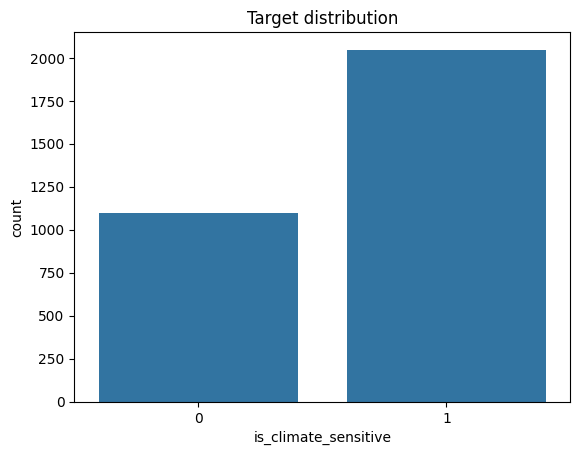

is_climate_sensitive
1    0.650668
0    0.349332
Name: proportion, dtype: float64


In [ ]:
sns.countplot(x='is_climate_sensitive', data=train)
plt.title('Target distribution')
plt.show()

print(train['is_climate_sensitive'].value_counts(normalize=True))

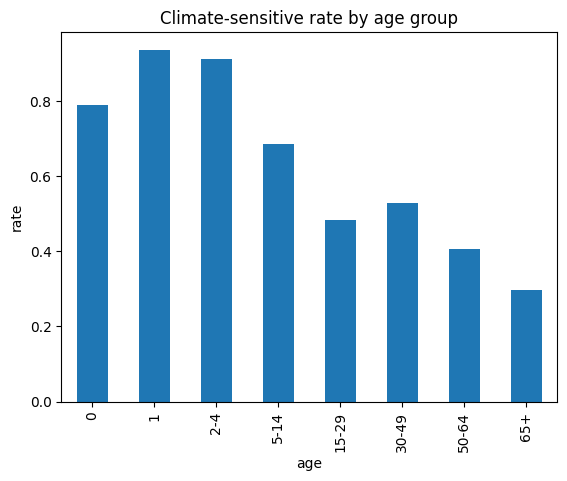

In [ ]:
age_groups = pd.cut(train['age'], bins=[-1, 0, 1, 4, 14, 29, 49, 64, 200],
                    labels=['0', '1', '2-4', '5-14', '15-29', '30-49', '50-64', '65+'])

train.groupby(age_groups)['is_climate_sensitive'].mean().plot(kind='bar')
plt.title('Climate-sensitive rate by age group')
plt.ylabel('rate')
plt.show()

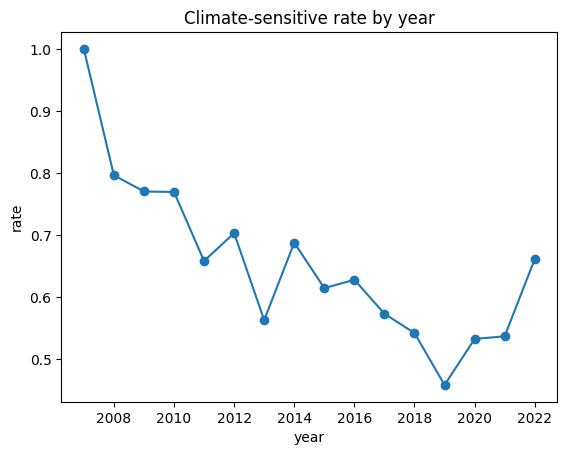

In [ ]:
train['year'] = pd.to_datetime(train['deathdate']).dt.year

train.groupby('year')['is_climate_sensitive'].mean().plot(marker='o')
plt.title('Climate-sensitive rate by year')
plt.ylabel('rate')
plt.show()

In [ ]:
train_villages = set(train['location'])
test_villages = set(test['location'])

print("Villages in train:", len(train_villages))
print("Villages in test:", len(test_villages))
print("Villages in both:", len(train_villages & test_villages))

Villages in train: 39
Villages in test: 11
Villages in both: 1


In [ ]:
data = pd.concat([train, test]).reset_index(drop=True)

data['deathdate'] = pd.to_datetime(data['deathdate'])

data['year'] = data['deathdate'].dt.year
data['month'] = data['deathdate'].dt.month
data['day_of_year'] = data['deathdate'].dt.dayofyear

data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)

data['after_2017'] = (data['year'] >= 2017).astype(int)

data['is_infant'] = (data['age'] == 0).astype(int)
data['is_under5'] = (data['age'] < 5).astype(int)
data['is_elderly'] = (data['age'] >= 65).astype(int)
data['infant_post2017'] = data['is_infant'] * data['after_2017']

data['male'] = (data['gender'] == 'Male').astype(int)
data['rural'] = (data['zone'] == 'Rural').astype(int)

data['lat4'] = data['latitude'].round(4)
data['lon4'] = data['longitude'].round(4)

data.head()

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,...,month_cos,after_2017,is_infant,is_under5,is_elderly,infant_post2017,male,rural,lat4,lon4
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,...,0.500000,0,0,0,0,0,1,1,0.5846,33.5463
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,...,0.866025,0,0,1,0,0,1,1,0.5496,33.4903
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,...,0.500000,0,0,0,0,0,0,1,0.5734,33.4837
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,...,0.500000,0,0,1,0,0,0,1,0.5496,33.4903
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,...,0.500000,0,0,0,1,0,0,1,1.0723,34.2266


In [ ]:
base_features = ['age', 'is_infant', 'is_under5', 'is_elderly', 'male', 'rural',
                 'year', 'month', 'day_of_year', 'month_sin', 'month_cos',
                 'after_2017', 'infant_post2017']

In [ ]:
weather_file = 'nasa_power_daily.csv'

if os.path.exists(weather_file):
    weather = pd.read_csv(weather_file, parse_dates=['date'])
else:
    locations = data[['lat4', 'lon4']].drop_duplicates().values
    all_weather = []

    for i, (lat, lon) in enumerate(locations):
        url = ('https://power.larc.nasa.gov/api/temporal/daily/point'
               '?parameters=T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,QV2M,WS2M&community=AG'
               f'&longitude={lon}&latitude={lat}&start=20070101&end=20221231&format=JSON')

        for attempt in range(4):
            try:
                response = requests.get(url, timeout=180)
                response.raise_for_status()
                break
            except Exception as e:
                print('retry', i, e)
                time.sleep(10)

        df = pd.DataFrame(response.json()['properties']['parameter'])
        df.index = pd.to_datetime(df.index, format='%Y%m%d')
        df = df.replace(-999, np.nan)
        df['lat4'] = lat
        df['lon4'] = lon
        all_weather.append(df.rename_axis('date').reset_index())

        print(f'{i+1}/{len(locations)} done')
        time.sleep(1)

    weather = pd.concat(all_weather, ignore_index=True)
    weather.to_csv(weather_file, index=False)

print(weather.shape)
weather.head()

(321420, 10)


,date,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,QV2M,WS2M,lat4,lon4
0,2007-01-01,22.58,27.94,18.42,68.31,0.41,12.87,1.43,0.5846,33.5463
1,2007-01-02,22.46,28.26,15.97,68.30,0.75,12.78,1.14,0.5846,33.5463
2,2007-01-03,22.49,28.10,16.79,74.33,1.75,14.01,1.66,0.5846,33.5463
3,2007-01-04,22.78,27.01,19.51,78.36,2.64,15.19,1.57,0.5846,33.5463
4,2007-01-05,22.29,28.30,16.30,69.45,0.17,12.76,1.46,0.5846,33.5463


In [ ]:
weather_features = []

for (lat, lon), w in weather.groupby(['lat4', 'lon4']):
    w = w.sort_values('date').set_index('date')
    f = pd.DataFrame(index=w.index)

    for col in ['T2M', 'T2M_MAX', 'RH2M', 'QV2M', 'PRECTOTCORR']:
        f[f'p_{col}_7d'] = w[col].rolling(7, min_periods=1).mean()
        f[f'p_{col}_30d'] = w[col].rolling(30, min_periods=1).mean()

    f['p_rain_14d_sum'] = w['PRECTOTCORR'].rolling(14, min_periods=1).sum()
    f['p_wetdays_30d'] = (w['PRECTOTCORR'] > 1).astype(float).rolling(30, min_periods=1).sum()

    monthly_normal = w.groupby(w.index.month)[['T2M', 'RH2M', 'PRECTOTCORR']].transform('mean')
    for col in ['T2M', 'RH2M', 'PRECTOTCORR']:
        f[f'p_{col}_anom30'] = (w[col] - monthly_normal[col]).rolling(30, min_periods=1).mean()

    f['lat4'] = lat
    f['lon4'] = lon
    weather_features.append(f.rename_axis('date').reset_index())

weather_features = pd.concat(weather_features, ignore_index=True)
nasa_features = [c for c in weather_features.columns if c.startswith('p_')]

data = data.merge(weather_features, left_on=['lat4', 'lon4', 'deathdate'],
                  right_on=['lat4', 'lon4', 'date'], how='left')

print(len(nasa_features), 'NASA features')
print(f"There are {data[nasa_features].isna().sum().sum()} missing values in the NASA features.")

15 NASA features
There are 0 missing values in the NASA features.


In [ ]:
train_df = data[data['is_climate_sensitive'].notna()].reset_index(drop=True)
test_df = data[data['is_climate_sensitive'].isna()].reset_index(drop=True)

train_df['is_climate_sensitive'] = train_df['is_climate_sensitive'].astype(int)

print(train_df.shape, test_df.shape)

(3146, 59) (1030, 59)


In [ ]:
def competition_score(y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    return 0.6 * f1 + 0.4 * auc, f1, auc

In [ ]:
cat_params = {'iterations': 500, 'depth': 5, 'learning_rate': 0.03, 'verbose': 0}
lr_params = {'C': 0.5, 'max_iter': 5000}

In [ ]:
def cross_validate(features):
    X, y, groups = train_df[features], train_df['is_climate_sensitive'], train_df['location']

    lr_oof_all = []
    cat_oof_all = []

    for repeat in [0, 1, 2]:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=repeat)

        lr_oof = np.zeros(len(X))
        cat_oof = np.zeros(len(X))

        for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y, groups), 1):

            X_fold_train = X.iloc[train_idx]
            X_fold_valid = X.iloc[valid_idx]
            y_fold_train = y.iloc[train_idx]

            model1 = make_pipeline(StandardScaler(), LogisticRegression(**lr_params))
            model2 = CatBoostClassifier(**cat_params, random_seed=seed)

            model1.fit(X_fold_train, y_fold_train)
            model2.fit(X_fold_train, y_fold_train)

            lr_oof[valid_idx] = model1.predict_proba(X_fold_valid)[:, 1]
            cat_oof[valid_idx] = model2.predict_proba(X_fold_valid)[:, 1]

        lr_oof_all.append(lr_oof)
        cat_oof_all.append(cat_oof)

    return lr_oof_all, cat_oof_all


def average_score(oof_list):
    y = train_df['is_climate_sensitive']
    scores = [competition_score(y, oof) for oof in oof_list]
    return np.mean(scores, axis=0)

In [ ]:
lr_oof, cat_oof = cross_validate(base_features)

blend_oof = [(lr + cat) / 2 for lr, cat in zip(lr_oof, cat_oof)]

for name, oof in [('LogReg', lr_oof), ('CatBoost', cat_oof), ('Blend', blend_oof)]:
    score, f1, auc = average_score(oof)
    print(f"{name:9s} score={score:.4f}  F1={f1:.4f}  AUC={auc:.4f}")

LogReg    score=0.8093  F1=0.8063  AUC=0.8137
CatBoost  score=0.8102  F1=0.8056  AUC=0.8170
Blend     score=0.8146  F1=0.8108  AUC=0.8203


In [ ]:
lr_oof_w, cat_oof_w = cross_validate(base_features + nasa_features)
blend_oof_w = [(lr + cat) / 2 for lr, cat in zip(lr_oof_w, cat_oof_w)]

for name, oof in [('LogReg', lr_oof_w), ('CatBoost', cat_oof_w), ('Blend', blend_oof_w)]:
    score, f1, auc = average_score(oof)
    print(f"{name:9s} score={score:.4f}  F1={f1:.4f}  AUC={auc:.4f}")

LogReg    score=0.8074  F1=0.8050  AUC=0.8110
CatBoost  score=0.8048  F1=0.8011  AUC=0.8103
Blend     score=0.8095  F1=0.8057  AUC=0.8152


In [ ]:
X, y = train_df[base_features], train_df['is_climate_sensitive']

model1 = make_pipeline(StandardScaler(), LogisticRegression(**lr_params))
model1.fit(X, y)
lr_test_prob = model1.predict_proba(test_df[base_features])[:, 1]

cat_test_probs = []
for s in [0, 1, 2]:
    model2 = CatBoostClassifier(**cat_params, random_seed=seed + s)
    model2.fit(X, y)
    cat_test_probs.append(model2.predict_proba(test_df[base_features])[:, 1])

cat_test_prob = np.mean(cat_test_probs, axis=0)

final_pred_proba = (lr_test_prob + cat_test_prob) / 2
final_predictions = (final_pred_proba >= 0.5).astype(int)

print("Predicted climate-sensitive rate:", final_predictions.mean().round(3))

Predicted climate-sensitive rate: 0.701


In [ ]:
sub = pd.DataFrame({'ID': test_df['ID'],
                    'TargetF1': final_predictions,
                    'TargetRAUC': final_pred_proba})
sub.head()

,ID,TargetF1,TargetRAUC
0,ID_E760D84B,1,0.541250
1,ID_6EDEA907,1,0.743605
2,ID_B9FFC8D8,0,0.464431
3,ID_74C6C94E,0,0.437862
4,ID_0E02825D,1,0.724157


In [ ]:
sub.to_csv('sub_v2_logreg_catboost_blend.csv', index=False)
print(sub.shape)

(1030, 3)


In [ ]:
class_weight = 1.5

cat_params_v3 = {'iterations': 800, 'depth': 4, 'learning_rate': 0.02, 'l2_leaf_reg': 5, 'verbose': 0}

In [ ]:
from sklearn.preprocessing import SplineTransformer
from sklearn.compose import ColumnTransformer


def make_spline_logreg():
    other_features = [c for c in base_features if c not in ['age', 'year', 'day_of_year']]

    splines = ColumnTransformer([
        ('age', SplineTransformer(n_knots=8, degree=3), ['age']),
        ('year', SplineTransformer(n_knots=6, degree=3), ['year']),
        ('day', SplineTransformer(n_knots=6, degree=3, extrapolation='periodic'), ['day_of_year']),
        ('rest', 'passthrough', other_features)])

    return make_pipeline(splines, StandardScaler(),
                         LogisticRegression(C=0.5, max_iter=5000, class_weight={0: 1, 1: class_weight}))


def make_catboost_v3():
    return CatBoostClassifier(**cat_params_v3, class_weights=[1, class_weight], random_seed=seed)

In [ ]:
def cross_validate_one(make_model, features):
    X, y, groups = train_df[features], train_df['is_climate_sensitive'], train_df['location']
    all_oof = []

    for repeat in [0, 1, 2]:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=repeat)
        oof = np.zeros(len(X))

        for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y, groups), 1):

            X_fold_train = X.iloc[train_idx]
            X_fold_valid = X.iloc[valid_idx]
            y_fold_train = y.iloc[train_idx]

            model = make_model()
            model.fit(X_fold_train, y_fold_train)
            oof[valid_idx] = model.predict_proba(X_fold_valid)[:, 1]

        all_oof.append(oof)

    return all_oof


def show(name, oof_list):
    score, f1, auc = average_score(oof_list)
    print(f"{name:32s} score={score:.4f}  F1={f1:.4f}  AUC={auc:.4f}")


def blend(*oof_lists):
    return [np.mean(group, axis=0) for group in zip(*oof_lists)]

In [ ]:
spline_oof = cross_validate_one(make_spline_logreg, base_features)
cat_v3_oof = cross_validate_one(make_catboost_v3, base_features)

show('Spline LogReg', spline_oof)
show('CatBoost v3 (depth 4)', cat_v3_oof)
show('Blend v3 (spline + catboost)', blend(spline_oof, cat_v3_oof))

Spline LogReg                    score=0.8190  F1=0.8172  AUC=0.8217
CatBoost v3 (depth 4)            score=0.8175  F1=0.8160  AUC=0.8198
Blend v3 (spline + catboost)     score=0.8206  F1=0.8189  AUC=0.8232


In [ ]:
!pip -q install tabpfn

In [ ]:
from google.colab import userdata

try:
    os.environ['TABPFN_TOKEN'] = userdata.get('TABPFN_TOKEN')
    print('TabPFN key loaded')
except Exception as e:
    print('No key found, only TabPFN v2 will work ->', e)

TabPFN key loaded


In [ ]:
import torch
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running TabPFN on:', device)


def make_tabpfn_v2():
    return TabPFNClassifier.create_default_for_version(ModelVersion.V2, device=device, random_state=seed)


def make_tabpfn_v35():
    return TabPFNClassifier.create_default_for_version(ModelVersion.V3_5, device=device, random_state=seed)

Running TabPFN on: cuda


In [ ]:
start = time.time()
pfn_v2_oof = cross_validate_one(make_tabpfn_v2, base_features)
print(f'took {time.time() - start:.0f}s')

show('TabPFN v2', pfn_v2_oof)

tabpfn-v2-classifier-finetuned-zk73skhh.(…): reconstructing file:   0%|          |  0.00B / 29.0MB            

tabpfn-v2-classifier-finetuned-zk73skhh.(…): downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

took 40s
TabPFN v2                        score=0.8180  F1=0.8127  AUC=0.8261


In [ ]:
try:
    start = time.time()
    pfn_v35_oof = cross_validate_one(make_tabpfn_v35, base_features)
    print(f'took {time.time() - start:.0f}s')
    show('TabPFN v3.5', pfn_v35_oof)
except Exception as e:
    pfn_v35_oof = None
    print('TabPFN v3.5 skipped ->', e)

TabPFN v3.5 skipped -> TabPFN requires a one-time license acceptance to download
model weights for local inference, but no interactive terminal
is available.

To authenticate in a non-interactive environment:
  1. Open https://ux.priorlabs.ai in a browser and log in (or register)
  2. Accept the license on the Licenses tab
  3. Copy your API Key from https://ux.priorlabs.ai/account
  4. Set the environment variable: export TABPFN_TOKEN="<your-api-key>"
     or in Python (before calling .fit()): import os; os.environ["TABPFN_TOKEN"] = "<your-api-key>"


In [ ]:
show('Blend v3 (spline + catboost)', blend(spline_oof, cat_v3_oof))
show('spline + catboost + pfn v2', blend(spline_oof, cat_v3_oof, pfn_v2_oof))
show('spline + pfn v2', blend(spline_oof, pfn_v2_oof))

if pfn_v35_oof is not None:
    show('spline + catboost + pfn v3.5', blend(spline_oof, cat_v3_oof, pfn_v35_oof))
    show('spline + pfn v3.5', blend(spline_oof, pfn_v35_oof))
    show('spline + catboost + pfn v2 + v3.5', blend(spline_oof, cat_v3_oof, pfn_v2_oof, pfn_v35_oof))

Blend v3 (spline + catboost)     score=0.8206  F1=0.8189  AUC=0.8232
spline + catboost + pfn v2       score=0.8203  F1=0.8172  AUC=0.8250
spline + pfn v2                  score=0.8205  F1=0.8173  AUC=0.8253


In [ ]:
final_models = ['spline', 'catboost', 'pfn_v2']

In [ ]:
X, y = train_df[base_features], train_df['is_climate_sensitive']
X_test = test_df[base_features]

test_probs = {}

model = make_spline_logreg()
model.fit(X, y)
test_probs['spline'] = model.predict_proba(X_test)[:, 1]

cat_preds = []
for s in [0, 1, 2]:
    model = CatBoostClassifier(**cat_params_v3, class_weights=[1, class_weight], random_seed=seed + s)
    model.fit(X, y)
    cat_preds.append(model.predict_proba(X_test)[:, 1])
test_probs['catboost'] = np.mean(cat_preds, axis=0)

if 'pfn_v2' in final_models:
    model = make_tabpfn_v2()
    model.fit(X, y)
    test_probs['pfn_v2'] = model.predict_proba(X_test)[:, 1]

if 'pfn_v35' in final_models:
    model = make_tabpfn_v35()
    model.fit(X, y)
    test_probs['pfn_v35'] = model.predict_proba(X_test)[:, 1]

final_pred_proba = np.mean([test_probs[m] for m in final_models], axis=0)
final_predictions = (final_pred_proba >= 0.5).astype(int)

print('Models used:', final_models)
print('Predicted climate-sensitive rate:', final_predictions.mean().round(3))

Models used: ['spline', 'catboost', 'pfn_v2']
Predicted climate-sensitive rate: 0.77


In [ ]:
X, y = train_df[base_features], train_df['is_climate_sensitive']
X_test = test_df[base_features]

model = make_tabpfn_v35()
model.fit(X, y)
pfn_v35_test = model.predict_proba(X_test)[:, 1]

v6_proba = (test_probs['spline'] + test_probs['catboost'] + test_probs['pfn_v2'] + pfn_v35_test) / 4
v6_predictions = (v6_proba >= 0.5).astype(int)
print('Predicted climate-sensitive rate:', v6_predictions.mean().round(3))

sub_v6 = pd.DataFrame({'ID': test_df['ID'],
                       'TargetF1': v6_predictions,
                       'TargetRAUC': v6_proba})
sub_v6.to_csv('sub_v6_spline_catboost_pfn_v2_pfn_v35.csv', index=False)
print('sub_v6 saved', sub_v6.shape)

Predicted climate-sensitive rate: 0.742
sub_v6 saved (1030, 3)


In [ ]:
sub = pd.DataFrame({'ID': test_df['ID'],
                    'TargetF1': final_predictions,
                    'TargetRAUC': final_pred_proba})

file_name = 'sub_v4_' + '_'.join(final_models) + '.csv'
sub.to_csv(file_name, index=False)
print(file_name, sub.shape)

sub_v4_spline_catboost_pfn_v2.csv (1030, 3)


In [ ]:
class_weight = 1.0

spline_oof_nw = cross_validate_one(make_spline_logreg, base_features)
cat_oof_nw = cross_validate_one(make_catboost_v3, base_features)

show('spline + catboost (no weight)', blend(spline_oof_nw, cat_oof_nw))
show('spline + catboost + pfn v2 (no weight)', blend(spline_oof_nw, cat_oof_nw, pfn_v2_oof))

spline + catboost (no weight)    score=0.8142  F1=0.8084  AUC=0.8229
spline + catboost + pfn v2 (no weight) score=0.8164  F1=0.8109  AUC=0.8247


In [ ]:
X, y = train_df[base_features], train_df['is_climate_sensitive']
X_test = test_df[base_features]

model = make_spline_logreg()
model.fit(X, y)
spline_nw_test = model.predict_proba(X_test)[:, 1]

cat_preds = []
for s in [0, 1, 2]:
    model = CatBoostClassifier(**cat_params_v3, class_weights=[1, class_weight], random_seed=seed + s)
    model.fit(X, y)
    cat_preds.append(model.predict_proba(X_test)[:, 1])
cat_nw_test = np.mean(cat_preds, axis=0)

final_pred_proba = (spline_nw_test + cat_nw_test + test_probs['pfn_v2']) / 3
final_predictions = (final_pred_proba >= 0.5).astype(int)
print('Predicted climate-sensitive rate:', final_predictions.mean().round(3))

sub = pd.DataFrame({'ID': test_df['ID'],
                    'TargetF1': final_predictions,
                    'TargetRAUC': final_pred_proba})
sub.to_csv('sub_v5_noweight_spline_catboost_pfn_v2.csv', index=False)
print(sub.shape)

Predicted climate-sensitive rate: 0.691
(1030, 3)


In [ ]:
class_weight = 1.5


class WeightedTabPFN:
    def __init__(self, make_model, weight):
        self.model = make_model()
        self.weight = weight

    def fit(self, X, y):
        positives = X[y == 1]
        extra = positives.sample(frac=self.weight - 1, random_state=seed)
        X_new = pd.concat([X, extra])
        y_new = pd.concat([y, y.loc[extra.index]])
        self.model.fit(X_new, y_new)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)


def make_weighted_pfn_v2():
    return WeightedTabPFN(make_tabpfn_v2, class_weight)


def make_weighted_pfn_v35():
    return WeightedTabPFN(make_tabpfn_v35, class_weight)

In [ ]:
start = time.time()
pfn_v2w_oof = cross_validate_one(make_weighted_pfn_v2, base_features)
print(f'took {time.time() - start:.0f}s')

show('TabPFN v2 (weighted)', pfn_v2w_oof)

took 50s
TabPFN v2 (weighted)             score=0.8184  F1=0.8161  AUC=0.8218


In [ ]:
try:
    start = time.time()
    pfn_v35_oof = cross_validate_one(make_tabpfn_v35, base_features)
    pfn_v35w_oof = cross_validate_one(make_weighted_pfn_v35, base_features)
    print(f'took {time.time() - start:.0f}s')

    show('TabPFN v3.5', pfn_v35_oof)
    show('TabPFN v3.5 (weighted)', pfn_v35w_oof)
except Exception as e:
    pfn_v35_oof, pfn_v35w_oof = None, None
    print('TabPFN v3.5 skipped ->', e)

tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

took 122s
TabPFN v3.5                      score=0.8180  F1=0.8119  AUC=0.8272
TabPFN v3.5 (weighted)           score=0.7938  F1=0.7767  AUC=0.8194


In [ ]:
show('v4: spline + catboost + pfn v2', blend(spline_oof, cat_v3_oof, pfn_v2_oof))
show('spline + catboost + pfn v2 weighted', blend(spline_oof, cat_v3_oof, pfn_v2w_oof))

if pfn_v35_oof is not None:
    show('spline + catboost + pfn v3.5', blend(spline_oof, cat_v3_oof, pfn_v35_oof))
    show('spline + catboost + pfn v3.5 weighted', blend(spline_oof, cat_v3_oof, pfn_v35w_oof))
    show('spline + catboost + pfn v2w + v3.5w', blend(spline_oof, cat_v3_oof, pfn_v2w_oof, pfn_v35w_oof))
    show('spline + pfn v3.5 weighted', blend(spline_oof, pfn_v35w_oof))

v4: spline + catboost + pfn v2   score=0.8203  F1=0.8172  AUC=0.8250
spline + catboost + pfn v2 weighted score=0.8196  F1=0.8165  AUC=0.8242
spline + catboost + pfn v3.5     score=0.8198  F1=0.8160  AUC=0.8254
spline + catboost + pfn v3.5 weighted score=0.8205  F1=0.8173  AUC=0.8253
spline + catboost + pfn v2w + v3.5w score=0.8202  F1=0.8168  AUC=0.8253
spline + pfn v3.5 weighted       score=0.8176  F1=0.8127  AUC=0.8250
